Aggregate data across hourly and daily reports, which will be saved in src/data/processed/aggregate_data.csv



In [81]:
import os
import pandas as pd

os.getcwd()

'/Users/annamynick/Library/CloudStorage/Dropbox-Personal/career/erdos-data-science/fall-2026-bad-mood-prediction/notebooks'

In [82]:
# specify where to put output
dt = pd.Timestamp.today().strftime("%Y%m%d")
save_dir = '../data/processed/'
save_path = save_dir + 'aggregate_data_' + dt + '.csv'
print(save_path)

../data/processed/aggregate_data_20261027.csv


In [83]:

daily = pd.read_csv('../data/raw/rais_anonymized/csv_rais_anonymized/daily_fitbit_sema_df_unprocessed.csv')
hourly = pd.read_csv('../data/raw/rais_anonymized/csv_rais_anonymized/hourly_fitbit_sema_df_unprocessed.csv')

/var/folders/j1/0nq47s453531d1krnhqky8sc0000gn/T/ipykernel_22309/1670763625.py:2: DtypeWarning: Columns (0: badgeType, 1: mindfulness_session, 2: bmi, 3: step_goal) have mixed types. Specify dtype option on import or set low_memory=False.
  hourly = pd.read_csv('../data/raw/rais_anonymized/csv_rais_anonymized/hourly_fitbit_sema_df_unprocessed.csv')


In [84]:
hourly.head(5)

,Unnamed: 0,id,date,hour,temperature,badgeType,calories,distance,activityType,bpm,...,TENSE/ANXIOUS,TIRED,ENTERTAINMENT,GYM,HOME,HOME_OFFICE,OTHER,OUTDOORS,TRANSIT,WORK/SCHOOL
0,0,621e2e8e67b776a24055b564,2021-05-24,0.0,-1.466659,NaN,89.04,98.3,NaN,66.874763,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,621e2e8e67b776a24055b564,2021-05-24,1.0,0.210289,NaN,65.62,0.0,NaN,58.711364,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,621e2e8e67b776a24055b564,2021-05-24,2.0,-1.359378,NaN,65.40,NaN,NaN,55.133495,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,621e2e8e67b776a24055b564,2021-05-24,3.0,-0.316295,NaN,69.01,11.0,NaN,60.488613,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,621e2e8e67b776a24055b564,2021-05-24,4.0,0.416455,NaN,65.73,0.0,NaN,59.110638,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [85]:
# define bad mood and good mood columns 
bad_cols  = ['SAD', 'TENSE/ANXIOUS', 'TIRED']
good_cols = ['NEUTRAL', 'ALERT', 'HAPPY', 'RESTED/RELAXED']

# make a new dataframe called df which is the aggregate data, using hourly and daily data 
df = hourly.copy(); 
df['BAD_MOOD']  = df[bad_cols].sum(axis=1, min_count=1)
df['GOOD_MOOD'] = df[good_cols].sum(axis=1, min_count=1)

# check
df.head(20)

,Unnamed: 0,id,date,hour,temperature,badgeType,calories,distance,activityType,bpm,...,ENTERTAINMENT,GYM,HOME,HOME_OFFICE,OTHER,OUTDOORS,TRANSIT,WORK/SCHOOL,BAD_MOOD,GOOD_MOOD
0,0,621e2e8e67b776a24055b564,2021-05-24,0.0,-1.466659,NaN,89.04,98.3,NaN,66.874763,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,621e2e8e67b776a24055b564,2021-05-24,1.0,0.210289,NaN,65.62,0.0,NaN,58.711364,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,621e2e8e67b776a24055b564,2021-05-24,2.0,-1.359378,NaN,65.40,NaN,NaN,55.133495,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,621e2e8e67b776a24055b564,2021-05-24,3.0,-0.316295,NaN,69.01,11.0,NaN,60.488613,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,621e2e8e67b776a24055b564,2021-05-24,4.0,0.416455,NaN,65.73,0.0,NaN,59.110638,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,5,621e2e8e67b776a24055b564,2021-05-24,5.0,-0.836378,NaN,65.40,NaN,NaN,57.481481,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,6,621e2e8e67b776a24055b564,2021-05-24,6.0,-0.677295,NaN,70.87,28.8,NaN,59.402020,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,7,621e2e8e67b776a24055b564,2021-05-24,7.0,0.149622,NaN,65.73,0.0,NaN,61.217131,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,8,621e2e8e67b776a24055b564,2021-05-24,8.0,0.469372,NaN,67.48,5.1,NaN,60.842478,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,9,621e2e8e67b776a24055b564,2021-05-24,9.0,-2.527628,NaN,75.61,7.3,NaN,73.804527,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [86]:
df.shape
df.columns

Index(['Unnamed: 0', 'id', 'date', 'hour', 'temperature', 'badgeType',
       'calories', 'distance', 'activityType', 'bpm', 'mindfulness_session',
       'scl_avg', 'steps', 'minutes_in_default_zone_1',
       'minutes_below_default_zone_1', 'minutes_in_default_zone_2',
       'minutes_in_default_zone_3', 'age', 'gender', 'bmi', 'step_goal',
       'min_goal', 'max_goal', 'step_goal_label', 'ALERT', 'HAPPY', 'NEUTRAL',
       'RESTED/RELAXED', 'SAD', 'TENSE/ANXIOUS', 'TIRED', 'ENTERTAINMENT',
       'GYM', 'HOME', 'HOME_OFFICE', 'OTHER', 'OUTDOORS', 'TRANSIT',
       'WORK/SCHOOL', 'BAD_MOOD', 'GOOD_MOOD'],
      dtype='str')

In [87]:
# make a new column called time_since_badmood which subtracts the current  (date and hour) from the subjects' most recent (previous) 

df["timestamp"] = pd.to_datetime(df["date"]) + pd.to_timedelta(df["hour"], unit="h")
df[['hour','date','timestamp']].head(10)

,hour,date,timestamp
0,0.0,2021-05-24,2021-05-24 00:00:00
1,1.0,2021-05-24,2021-05-24 01:00:00
2,2.0,2021-05-24,2021-05-24 02:00:00
3,3.0,2021-05-24,2021-05-24 03:00:00
4,4.0,2021-05-24,2021-05-24 04:00:00
5,5.0,2021-05-24,2021-05-24 05:00:00
6,6.0,2021-05-24,2021-05-24 06:00:00
7,7.0,2021-05-24,2021-05-24 07:00:00
8,8.0,2021-05-24,2021-05-24 08:00:00
9,9.0,2021-05-24,2021-05-24 09:00:00


In [88]:
df['BAD_MOOD'].unique()

array([nan,  0.,  1.])

In [89]:
df = df.sort_values(["id", "timestamp"]).copy()

last_badmood_time = (
    df["timestamp"]
    .where(df["BAD_MOOD"].eq(1))  # Use .eq(True) if bad_mood is boolean
    .groupby(df["id"])
    .ffill()
)

last_badmood_time[1000:1010]

75121   2021-06-28 16:00:00
75122   2021-06-28 16:00:00
75123   2021-06-28 16:00:00
75124   2021-06-28 16:00:00
75125   2021-06-28 16:00:00
75126   2021-06-28 16:00:00
75127   2021-06-28 16:00:00
75128   2021-06-28 16:00:00
828     2021-06-28 16:00:00
829     2021-06-28 16:00:00
Name: timestamp, dtype: datetime64[us]

In [90]:
# time since participants' last bad mood 
df["time_since_badmood"] = df["timestamp"] - last_badmood_time

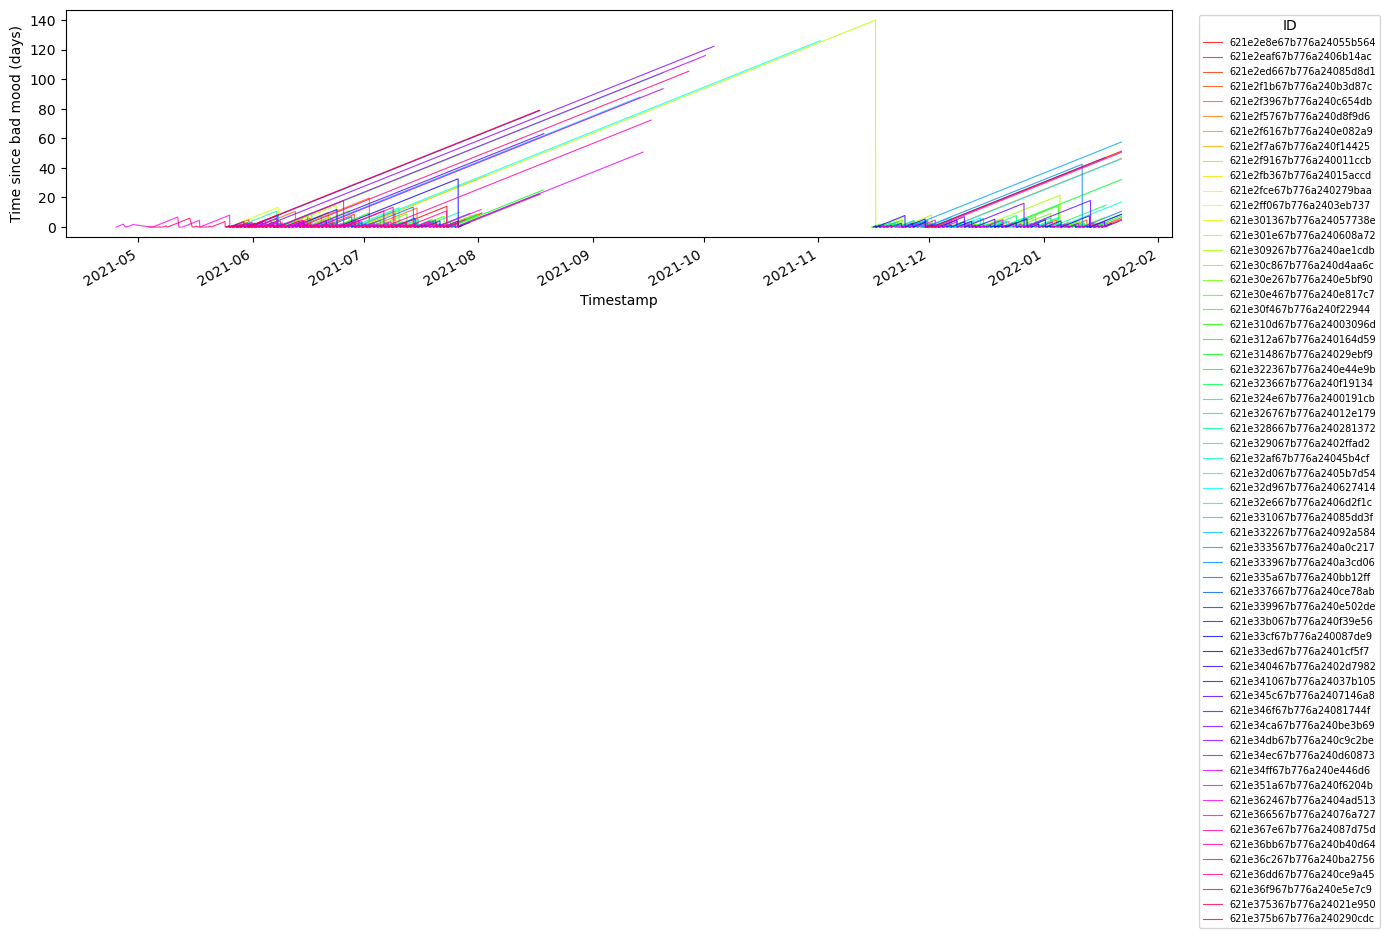

In [91]:
# make a plot showing time since participants' last bad mood 
import matplotlib.pyplot as plt

plot_df = df.dropna(subset=["id", "timestamp", "time_since_badmood"]).copy()
plot_df["days_since_badmood"] = plot_df["time_since_badmood"].dt.total_seconds() / 86400

ids = plot_df["id"].unique()
fig, ax = plt.subplots(figsize=(14, 7))

for i, (participant_id, group) in enumerate(plot_df.groupby("id", sort=False)):
    group = group.sort_values("timestamp")
    ax.plot(
        group["timestamp"],
        group["days_since_badmood"],
        color=plt.cm.hsv(i / max(len(ids), 1)),
        label=str(participant_id),
        linewidth=0.8,
        alpha=0.8,
    )

ax.set_xlabel("Timestamp")
ax.set_ylabel("Time since bad mood (days)")
ax.legend(title="ID", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [92]:
# make time since last good mood 
last_goodmood_time = (
    df["timestamp"]
    .where(df["GOOD_MOOD"].eq(1))  # Use .eq(True) if bad_mood is boolean
    .groupby(df["id"])
    .ffill()
)

# time since participants' last good mood 
df["time_since_badmood"] = df["timestamp"] - last_goodmood_time


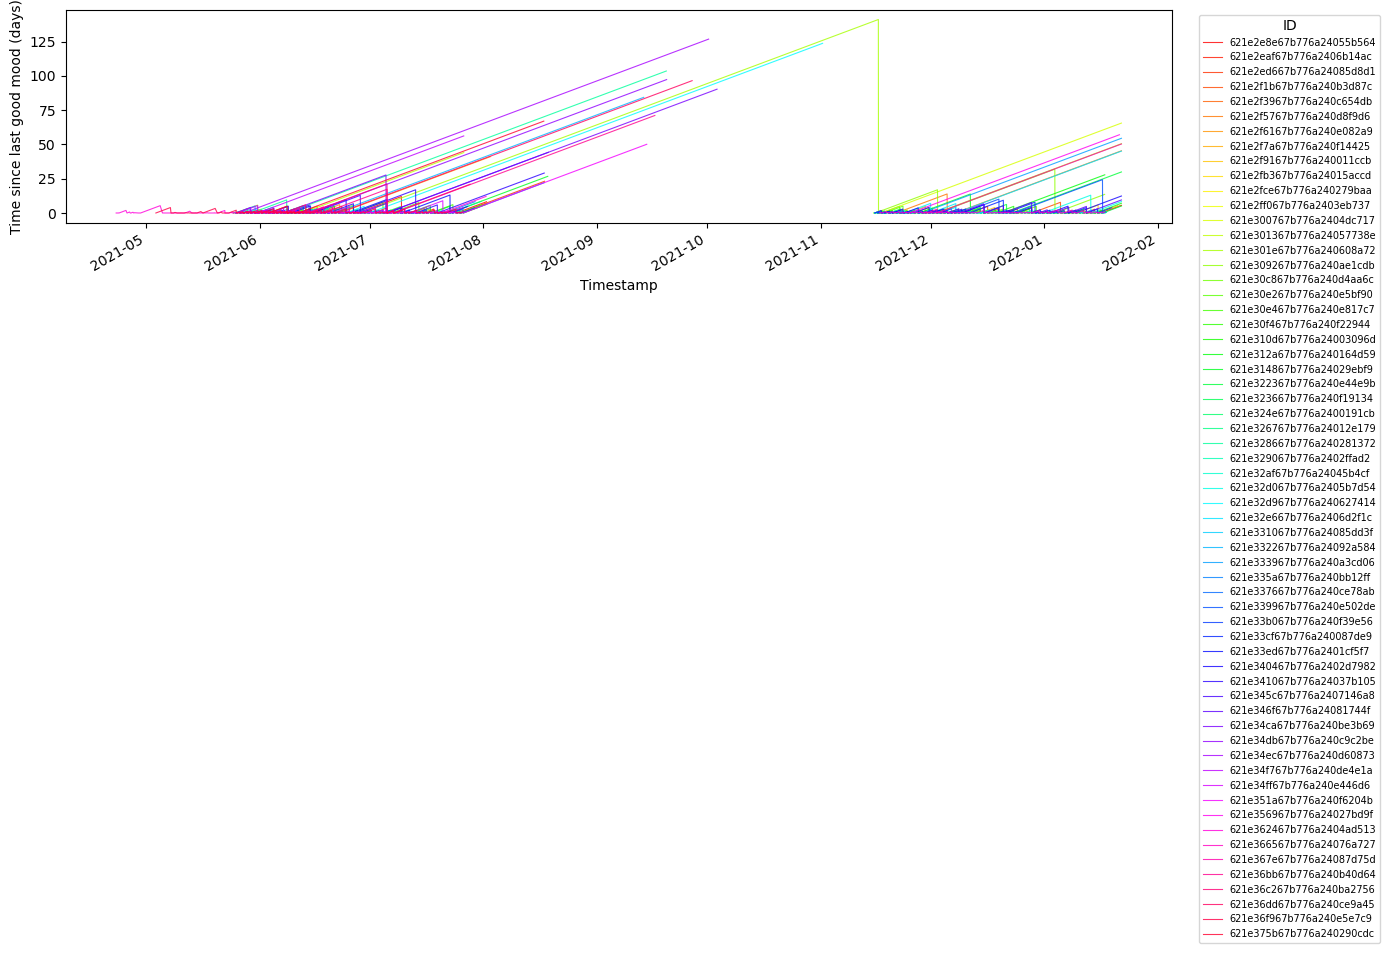

In [93]:
# Make a plot showing time since participants' last good mood
df["time_since_goodmood"] = df["timestamp"] - last_goodmood_time

plot_df = df.dropna(subset=["id", "timestamp", "time_since_goodmood"]).copy()
plot_df["days_since_goodmood"] = (
    plot_df["time_since_goodmood"].dt.total_seconds() / 86400
)

ids = plot_df["id"].unique()
fig, ax = plt.subplots(figsize=(14, 7))

for i, (participant_id, group) in enumerate(plot_df.groupby("id", sort=False)):
    group = group.sort_values("timestamp")
    ax.plot(
        group["timestamp"],
        group["days_since_goodmood"],
        color=plt.cm.hsv(i / max(len(ids), 1)),
        label=str(participant_id),
        linewidth=0.8,
        alpha=0.8,
    )

ax.set_xlabel("Timestamp")
ax.set_ylabel("Time since last good mood (days)")
ax.legend(title="ID", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [94]:
# make columns logging the time until subjects' next bad/good mood 
next_badmood_time = (
    df["timestamp"]
    .where(df["BAD_MOOD"].eq(1))
    .groupby(df["id"], sort=False)
    .shift(-1)
    .groupby(df["id"], sort=False)
    .bfill()
)

df["time_until_badmood"] = next_badmood_time - df["timestamp"]

next_badmood_time = (
    df["timestamp"]
    .where(df["BAD_MOOD"].eq(1))
    .groupby(df["id"], sort=False)
    .shift(-1)
    .groupby(df["id"], sort=False)
    .bfill()
)

df["time_until_badmood"] = next_badmood_time - df["timestamp"]

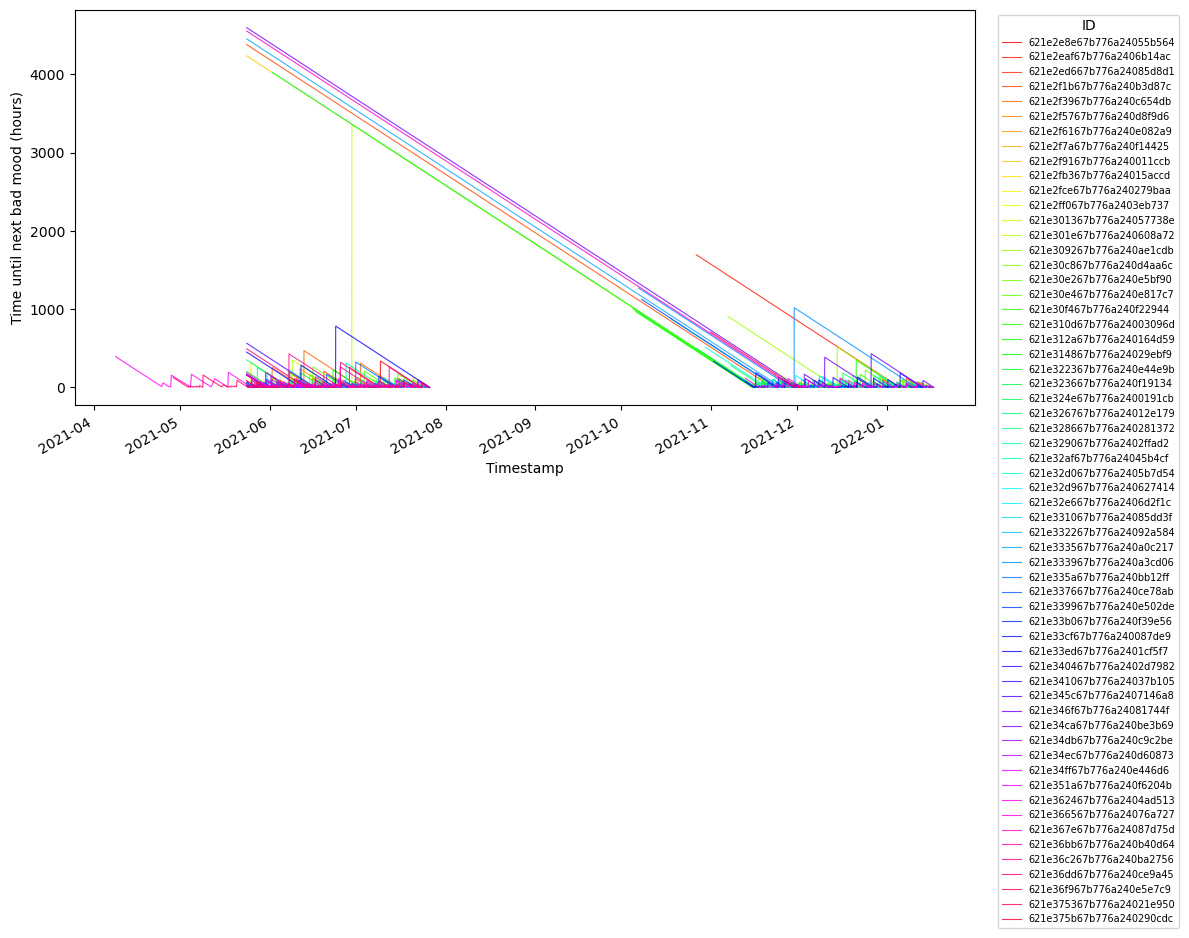

In [95]:
# Plot time until subjects' next bad mood against timestamp
plot_until_df = df.dropna(
    subset=["id", "timestamp", "time_until_badmood"]
).copy()
plot_until_df["hours_until_badmood"] = (
    plot_until_df["time_until_badmood"].dt.total_seconds() / 3600
)

participant_ids = plot_until_df["id"].unique()
fig, ax = plt.subplots(figsize=(12, 8))

for i, (participant_id, group) in enumerate(
    plot_until_df.groupby("id", sort=False)
):
    group = group.sort_values("timestamp")
    ax.plot(
        group["timestamp"],
        group["hours_until_badmood"],
        color=plt.cm.hsv(i / max(len(participant_ids), 1)),
        label=str(participant_id),
        linewidth=0.8,
        alpha=0.8,
    )

ax.set_xlabel("Timestamp")
ax.set_ylabel("Time until next bad mood (hours)")
ax.legend(title="ID", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

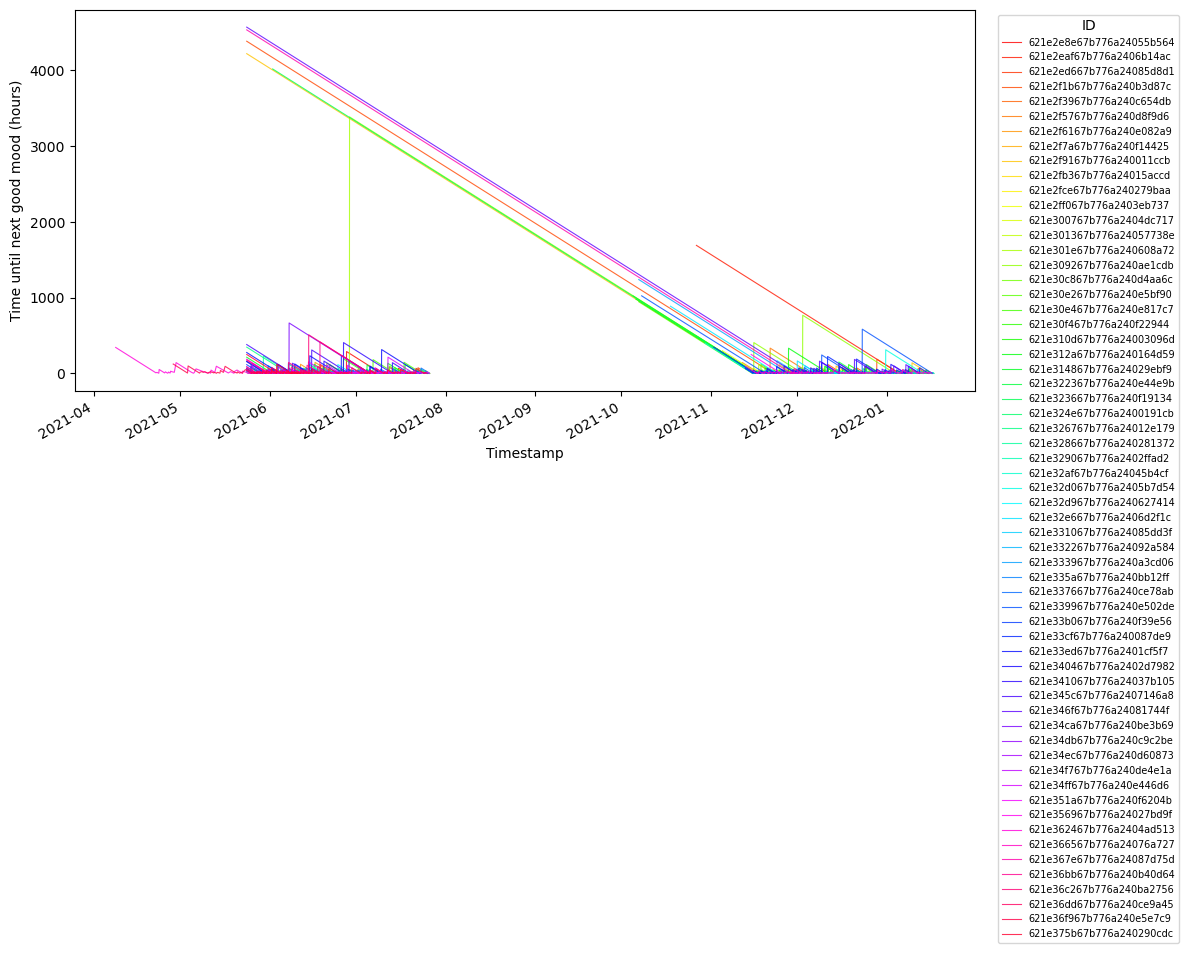

In [96]:
# Plot time until subjects' next good mood against timestamp
next_goodmood_time = (
    df["timestamp"]
    .where(df["GOOD_MOOD"].eq(1))
    .groupby(df["id"], sort=False)
    .shift(-1)
    .groupby(df["id"], sort=False)
    .bfill()
)

df["time_until_goodmood"] = next_goodmood_time - df["timestamp"]

plot_until_df = df.dropna(
    subset=["id", "timestamp", "time_until_goodmood"]
).copy()
plot_until_df["hours_until_goodmood"] = (
    plot_until_df["time_until_goodmood"].dt.total_seconds() / 3600
)

participant_ids = plot_until_df["id"].unique()
fig, ax = plt.subplots(figsize=(12, 8))

for i, (participant_id, group) in enumerate(
    plot_until_df.groupby("id", sort=False)
):
    group = group.sort_values("timestamp")
    ax.plot(
        group["timestamp"],
        group["hours_until_goodmood"],
        color=plt.cm.hsv(i / max(len(participant_ids), 1)),
        label=str(participant_id),
        linewidth=0.8,
        alpha=0.8,
    )

ax.set_xlabel("Timestamp")
ax.set_ylabel("Time until next good mood (hours)")
ax.legend(title="ID", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [97]:
daily.columns

Index(['Unnamed: 0', 'id', 'date', 'nightly_temperature', 'nremhr', 'rmssd',
       'spo2', 'full_sleep_breathing_rate', 'stress_score',
       'sleep_points_percentage', 'exertion_points_percentage',
       'responsiveness_points_percentage', 'daily_temperature_variation',
       'badgeType', 'calories', 'filteredDemographicVO2Max', 'distance',
       'activityType', 'bpm', 'lightly_active_minutes',
       'moderately_active_minutes', 'very_active_minutes', 'sedentary_minutes',
       'mindfulness_session', 'scl_avg', 'resting_hr', 'sleep_duration',
       'minutesToFallAsleep', 'minutesAsleep', 'minutesAwake',
       'minutesAfterWakeup', 'sleep_efficiency', 'sleep_deep_ratio',
       'sleep_wake_ratio', 'sleep_light_ratio', 'sleep_rem_ratio', 'steps',
       'minutes_in_default_zone_1', 'minutes_below_default_zone_1',
       'minutes_in_default_zone_2', 'minutes_in_default_zone_3', 'age',
       'gender', 'bmi', 'step_goal', 'min_goal', 'max_goal', 'step_goal_label',
       'ALERT',

In [98]:
hourly.columns
hourly['date']

0         2021-05-24
1         2021-05-24
2         2021-05-24
3         2021-05-24
4         2021-05-24
             ...    
159503    2021-05-22
159504    2021-05-23
159505    2021-11-19
159506    2021-11-19
159507    2021-11-20
Name: date, Length: 159508, dtype: str

In [99]:
# combine hourly and daily data

In [100]:
matching_columns = daily.columns.intersection(df.columns).tolist()
print(matching_columns)

['Unnamed: 0', 'id', 'date', 'badgeType', 'calories', 'distance', 'activityType', 'bpm', 'mindfulness_session', 'scl_avg', 'steps', 'minutes_in_default_zone_1', 'minutes_below_default_zone_1', 'minutes_in_default_zone_2', 'minutes_in_default_zone_3', 'age', 'gender', 'bmi', 'step_goal', 'min_goal', 'max_goal', 'step_goal_label', 'ALERT', 'HAPPY', 'NEUTRAL', 'RESTED/RELAXED', 'SAD', 'TENSE/ANXIOUS', 'TIRED', 'ENTERTAINMENT', 'GYM', 'HOME', 'HOME_OFFICE', 'OTHER', 'OUTDOORS', 'TRANSIT', 'WORK/SCHOOL']


In [101]:
unique_daily_columns = [col for col in daily.columns if col not in matching_columns]
print(unique_daily_columns)

['nightly_temperature', 'nremhr', 'rmssd', 'spo2', 'full_sleep_breathing_rate', 'stress_score', 'sleep_points_percentage', 'exertion_points_percentage', 'responsiveness_points_percentage', 'daily_temperature_variation', 'filteredDemographicVO2Max', 'lightly_active_minutes', 'moderately_active_minutes', 'very_active_minutes', 'sedentary_minutes', 'resting_hr', 'sleep_duration', 'minutesToFallAsleep', 'minutesAsleep', 'minutesAwake', 'minutesAfterWakeup', 'sleep_efficiency', 'sleep_deep_ratio', 'sleep_wake_ratio', 'sleep_light_ratio', 'sleep_rem_ratio']


In [102]:
# add daily data to df (hourly data) here, adding a daily_ prefix to every column from the daily dataframe (so its clear where the data came from)
# n.b. this approach could cause data leakage if we tried to predict a subjects' future state from their current data, but won't create problems in predicting for other subjects
daily_values = daily[["id", "date", *unique_daily_columns]].copy()
daily_values["date"] = pd.to_datetime(daily_values["date"])
daily_values = daily_values.rename(
    columns={col: f"daily_{col}" for col in unique_daily_columns}
)

daily_lookup = df[["id"]].assign(date=pd.to_datetime(df["date"])).merge(
    daily_values,
    on=["id", "date"],
    how="left",
    sort=False,
    validate="many_to_one",
)

daily_cols = [f"daily_{col}" for col in unique_daily_columns]
df[daily_cols] = daily_lookup[daily_cols].to_numpy()



In [103]:
df

,Unnamed: 0,id,date,hour,temperature,badgeType,calories,distance,activityType,bpm,...,daily_sleep_duration,daily_minutesToFallAsleep,daily_minutesAsleep,daily_minutesAwake,daily_minutesAfterWakeup,daily_sleep_efficiency,daily_sleep_deep_ratio,daily_sleep_wake_ratio,daily_sleep_light_ratio,daily_sleep_rem_ratio
0,0,621e2e8e67b776a24055b564,2021-05-24,0.0,-1.466659,NaN,89.04,98.3,NaN,66.874763,...,31260000.0,0.0,445.0,76.0,0.0,93.0,1.243243,0.987013,0.921642,1.341772
1,1,621e2e8e67b776a24055b564,2021-05-24,1.0,0.210289,NaN,65.62,0.0,NaN,58.711364,...,31260000.0,0.0,445.0,76.0,0.0,93.0,1.243243,0.987013,0.921642,1.341772
2,2,621e2e8e67b776a24055b564,2021-05-24,2.0,-1.359378,NaN,65.40,NaN,NaN,55.133495,...,31260000.0,0.0,445.0,76.0,0.0,93.0,1.243243,0.987013,0.921642,1.341772
3,3,621e2e8e67b776a24055b564,2021-05-24,3.0,-0.316295,NaN,69.01,11.0,NaN,60.488613,...,31260000.0,0.0,445.0,76.0,0.0,93.0,1.243243,0.987013,0.921642,1.341772
4,4,621e2e8e67b776a24055b564,2021-05-24,4.0,0.416455,NaN,65.73,0.0,NaN,59.110638,...,31260000.0,0.0,445.0,76.0,0.0,93.0,1.243243,0.987013,0.921642,1.341772
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159082,159082,621e375b67b776a240290cdc,2021-08-17,7.0,NaN,NaN,54.00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
159083,159083,621e375b67b776a240290cdc,2021-08-17,8.0,NaN,NaN,54.00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
159084,159084,621e375b67b776a240290cdc,2021-08-17,9.0,NaN,NaN,54.00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
159085,159085,621e375b67b776a240290cdc,2021-08-17,10.0,NaN,NaN,54.00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [104]:
df.columns

Index(['Unnamed: 0', 'id', 'date', 'hour', 'temperature', 'badgeType',
       'calories', 'distance', 'activityType', 'bpm', 'mindfulness_session',
       'scl_avg', 'steps', 'minutes_in_default_zone_1',
       'minutes_below_default_zone_1', 'minutes_in_default_zone_2',
       'minutes_in_default_zone_3', 'age', 'gender', 'bmi', 'step_goal',
       'min_goal', 'max_goal', 'step_goal_label', 'ALERT', 'HAPPY', 'NEUTRAL',
       'RESTED/RELAXED', 'SAD', 'TENSE/ANXIOUS', 'TIRED', 'ENTERTAINMENT',
       'GYM', 'HOME', 'HOME_OFFICE', 'OTHER', 'OUTDOORS', 'TRANSIT',
       'WORK/SCHOOL', 'BAD_MOOD', 'GOOD_MOOD', 'timestamp',
       'time_since_badmood', 'time_since_goodmood', 'time_until_badmood',
       'time_until_goodmood', 'daily_nightly_temperature', 'daily_nremhr',
       'daily_rmssd', 'daily_spo2', 'daily_full_sleep_breathing_rate',
       'daily_stress_score', 'daily_sleep_points_percentage',
       'daily_exertion_points_percentage',
       'daily_responsiveness_points_percentage'

In [105]:
# save aggregate data to a file 
df.to_csv(save_path, index=False)
print(f"Saved to {save_path}")

Saved to ../data/processed/aggregate_data_20261027.csv


In [108]:
# check dave data 

savedf = pd.read_csv(save_path)
df.equals(savedf)

print(df.shape, savedf.shape)
print(df.columns.equals(savedf.columns), df.index.equals(savedf.index))
display(pd.concat([df.dtypes.rename("df"), savedf.dtypes.rename("savedf")], axis=1))


(159508, 72) (159508, 72)
True False


/var/folders/j1/0nq47s453531d1krnhqky8sc0000gn/T/ipykernel_22309/3952245288.py:3: DtypeWarning: Columns (0: mindfulness_session, 1: bmi, 2: step_goal) have mixed types. Specify dtype option on import or set low_memory=False.
  savedf = pd.read_csv(save_path)


,df,savedf
Unnamed: 0,int64,int64
id,str,str
date,str,str
hour,float64,float64
temperature,float64,float64
...,...,...
daily_sleep_efficiency,float64,float64
daily_sleep_deep_ratio,float64,float64
daily_sleep_wake_ratio,float64,float64
daily_sleep_light_ratio,float64,float64
